# 02. Geneformer 임베딩 vs PCA · Harmony · scVI — FM이 항상 이기는가?

**등급**: 🟢 Mac 로컬 (CPU) · **예상 시간**: Mac에서 약 10~15분, Colab(CPU 2코어)에서 약 27분 (scVI 학습 + 평가) · **선행**: 노트북 01을 먼저 실행해 `.cache/singlecell/`에 하위표본과 임베딩을 만들어 둔다 · **다운로드**: 없음

**질문**: 사전학습된 Geneformer(**zero-shot**: 이 데이터로 추가 학습·적합을 하지 않음. 단, 이 데이터가 사전학습 코퍼스에 포함되었는지는 확인하지 못했다)의 세포 임베딩은 13명의 PBMC에서 (1) **세포 유형을 보존**하고 (2) **기증자 배치 효과를 얼마나 섞는가**? 단순한 PCA, 배치 보정(Harmony), 이 데이터로 직접 학습하는 scVI와 비교하면 어떤가?

**설계 (결과를 보기 전에 정한 것)**
- 라벨: 원 논문의 거친 분류 `cell.type.coarse` 13종. 배치: 기증자 13명. 하위표본: 기증자당 ≤800세포.
- **주 비교 5종**: PCA(HVG) · Harmony(PCA, 기증자 보정) · scVI(기증자 보정) · Geneformer V1-10M(평균 풀링, 마지막에서 두 번째 층) · Geneformer V2-104M(`<cls>`, 마지막에서 두 번째 층; 공식 `EmbExtractor` 기본값). 그 밖의 층/풀링/무작위 초기화는 **민감도 분석**이며 test 지표를 보고 고르지 않는다.
- 지표: ① **기증자 단위 leave-one-donor-out(LODO) kNN** 세포 유형 macro-F1 (분류기 학습·중심화에 다른 12명만 사용) + 기증자 단위 부트스트랩 CI, ② KMeans(k=13) ARI/NMI, ③ 라벨 silhouette(ASW), ④ 배치 혼합: 같은 세포 유형 안에서 **기증자를 kNN으로 얼마나 맞히는가**(우연 대비 초과 정확도)와 scib식 ASW_batch.
- **공정성 주의**: Harmony/scVI는 기증자 라벨을 **입력으로 쓴다**. Geneformer는 이 데이터로 추가 학습하지 않는다(zero-shot; 사전학습 코퍼스 포함 여부는 미확인). PCA/Harmony/scVI는 held-out 기증자의 세포도 비지도로 함께 적합(transductive)했고 **세포 유형 라벨은 쓰지 않았다**. 반면 LODO 분류 안의 평균 중심화는 **훈련 기증자 12명의 평균만** 쓴다(fold별).

In [1]:
import os
import time
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_samples, silhouette_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
CACHE = (ROOT / ".cache") if ROOT is not None else Path("cache")
SC = CACHE / "singlecell"
SEED = 0
np.random.seed(SEED)
import importlib.metadata as md

print({k: md.version(k) for k in ["numpy", "scipy", "scikit-learn", "scanpy", "anndata", "scvi-tools", "harmonypy", "torch"]})
for need in ["pbmc_sub.h5ad", "geneformer_embeddings.npz"]:
    assert (SC / need).exists(), f"{SC / need} 가 없다 — 노트북 01을 먼저 실행하라"

sub = ad.read_h5ad(SC / "pbmc_sub.h5ad")
E = dict(np.load(SC / "geneformer_embeddings.npz"))
obs = sub.obs.copy()
assert all(v.shape[0] == sub.n_obs for v in E.values())
labels, donors, disease = obs.label.values, obs.donor.values, obs.disease.values
class_names = sorted(obs.label.unique())
donor_names = sorted(obs.donor.unique())
y = np.array([class_names.index(l) for l in labels])
print(sub.shape, "| 세포 유형", len(class_names), "| 기증자", len(donor_names))
print("임베딩:", {k: v.shape[1] for k, v in E.items()})

{'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'scanpy': '1.12.5', 'anndata': '0.13.4', 'scvi-tools': '1.5.2', 'harmonypy': '2.1.0', 'torch': '2.15.0'}


(10400, 24505) | 세포 유형 13 | 기증자 13
임베딩: {'v1_mean_L-2': 256, 'v1_mean_L-1': 256, 'v1rand_mean_L-2': 256, 'v1rand_mean_L-1': 256, 'v2_mean_L-2': 768, 'v2_mean_L-1': 768, 'v2_cls_L-2': 768, 'v2_cls_L-1': 768}


## 1. Baseline 만들기
- **PCA(HVG)**: 원시 카운트에서 `seurat_v3` HVG 2,000개 → 총합 1e4 정규화 → `log1p` → 표준화(최대 10) → PCA 50. 일반적인 scanpy 표준 절차다.
- **Harmony**: 위 PCA 50차원을 기증자별로 보정 (`harmonypy`).
- **scVI**: HVG 2,000개 원시 카운트, `batch_key="donor"`, 잠재 30차원, CPU 학습. (학습 에폭은 시간 때문에 제한했다.)

In [2]:
a = sub.copy()
sc.pp.filter_genes(a, min_cells=3)                      # 거의 검출되지 않는 유전자 제외 (HVG loess 적합의 안정성)
print("유전자: %d → %d (≥3 세포에서 검출)" % (sub.n_vars, a.n_vars))
sc.pp.highly_variable_genes(a, n_top_genes=2000, flavor="seurat_v3")
hvg = a.var.highly_variable.values
a.layers["counts"] = a.X.copy()
sc.pp.normalize_total(a, target_sum=1e4)
sc.pp.log1p(a)
a = a[:, hvg].copy()
sc.pp.scale(a, max_value=10)
sc.pp.pca(a, n_comps=50, random_state=SEED)
Z_pca = a.obsm["X_pca"].copy()
print("HVG:", int(hvg.sum()), "| PCA:", Z_pca.shape)

import logging

import harmonypy

logging.getLogger("harmonypy").setLevel(logging.WARNING)
ho = harmonypy.run_harmony(Z_pca, obs[["donor"]], "donor", random_state=SEED)
Z_harm = np.asarray(ho.Z_corr)
if Z_harm.shape[0] != Z_pca.shape[0]:
    Z_harm = Z_harm.T
print("Harmony:", Z_harm.shape)

유전자: 24505 → 22715 (≥3 세포에서 검출)


HVG: 2000 | PCA: (10400, 50)
Harmony: (10400, 50)


In [3]:
import scvi

scvi.settings.seed = SEED
av = ad.AnnData(X=a.layers["counts"].copy(), obs=obs[["donor"]].copy())
scvi.model.SCVI.setup_anndata(av, batch_key="donor")
vae = scvi.model.SCVI(av, n_latent=30)
t0 = time.time()
vae.train(max_epochs=150, accelerator="cpu", batch_size=256, enable_progress_bar=False)
Z_scvi = vae.get_latent_representation()
hist = vae.history["elbo_train"].values.ravel()
print("scVI: %.0f초 | ELBO(train) 첫/마지막 에폭: %.1f → %.1f | 잠재 %s" % (time.time() - t0, hist[0], hist[-1], Z_scvi.shape))

Seed set to 0


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=150` reached.


scVI: 130초 | ELBO(train) 첫/마지막 에폭: 441.3 → 251.5 | 잠재 (10400, 30)


## 2. 평가 함수
모든 임베딩은 같은 절차로 평가한다: **평균 중심화 → 행 L2 정규화**(코사인 거리). 같은 절차를 모든 임베딩에 적용해 공정성을 확보한다 (Geneformer 임베딩의 공통 평균 성분이 거리를 지배하는 문제를 줄인다). 평균은 데이터에서 추정하는 값이므로 LODO 분류에서는 **fold마다 훈련 기증자의 평균**만 쓰고, KMeans/silhouette처럼 훈련-테스트 구분이 없는 지표는 전체 평균을 쓴다. 중심화 없이 평가한 값은 6절 민감도에 따로 둔다.

- **LODO kNN**: 기증자 한 명을 통째로 빼고 나머지 12명의 세포로 kNN(k=15, 유사도 가중 타이브레이크) 분류기를 만들어 그 기증자의 세포 유형을 예측한다. 예측을 모아 macro-F1을 계산하고, **기증자 단위 부트스트랩**(13명을 복원추출 1,000회)으로 구간을 낸다. 모든 방법이 **같은 재표본**을 쓰므로 방법 간 차이(Δ)도 짝지어 구간을 낸다. 이 구간은 *이미 계산된 예측을 기증자 단위로 재표본*한 것이라 임베딩/분류기 재학습에 따른 변동은 담지 않는 **조건부 불확실성**이다. 재표본에서 어떤 클래스가 통째로 빠지면 그 클래스는 macro 평균에서 제외된다.
- **ARI/NMI**: 정규화 임베딩에 KMeans(k=13, `n_init=10`, 시드 3개의 평균 [최소~최대])를 적용. k를 정답 클래스 수로 준 것이라 낙관적이다.
- **ASW_label**: 세포 유형 라벨의 silhouette를 (s+1)/2로 [0,1]에 맞춘 값 (scib 정의).
- **주요 유형 macro-F1**: 세포가 300개 이상인 유형(8종)만 평균한 보조 지표. 희귀 유형의 흔들림에 덜 민감하다.
- **배치 혼합**: 같은 세포 유형(세포 100개 이상, 기증자 3명 이상) 안에서 5-fold 교차검증 kNN으로 **기증자 ID**를 맞히고, 우연(1/기증자 수) 대비 균형 정확도의 초과분을 세포 수 가중 평균한다. **작을수록 기증자가 잘 섞인 것**이다. ASW_batch는 scib 정의대로 같은 세포 유형 안에서 **세포별** `1 − |s_i|`(s_i = 기증자 라벨 silhouette)를 평균하고 세포 유형 간에는 단순 평균한다 (클수록 섞임).
- **질병 신호 보존(LODO)**: 질병 상태는 **기증자에 완전히 겹쳐 있다**(COVID 7명, 정상 6명). 같은 세포 유형 안에서 다른 기증자들로 학습해 held-out 기증자의 질병 상태를 예측한다. 기증자 보정이 질병 신호까지 지우는지 보려는 것이며 **배치와 생물학을 분리하지 못한다**는 사실을 보여주는 지표다.

In [4]:
def prep(Z, center=True):
    Z = np.asarray(Z, dtype=np.float64)
    if center:
        Z = Z - Z.mean(0)
    return Z / np.linalg.norm(Z, axis=1, keepdims=True)


def knn_vote(Ztr, ytr, Zte, n_classes, k=15):
    S = Zte @ Ztr.T
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    votes = np.zeros((len(Zte), n_classes))
    rows = np.arange(len(Zte))
    for j in range(k):
        np.add.at(votes, (rows, ytr[idx[:, j]]), 1.0 + 1e-3 * S[rows, idx[:, j]])
    return votes.argmax(1)


def fold_prep(Zraw, te, center=True):
    """훈련 기증자(~te)의 평균만으로 중심화 → 행 L2 정규화. (훈련, 테스트) 반환"""
    mu = Zraw[~te].mean(0) if center else 0.0
    return prep(Zraw[~te] - mu, False), prep(Zraw[te] - mu, False)


def lodo_celltype(Zraw, center=True):
    """기증자별 혼동행렬 (n_donors, C, C). 중심화는 fold별 훈련 기증자 평균."""
    C = len(class_names)
    cms = np.zeros((len(donor_names), C, C))
    for i, d in enumerate(donor_names):
        te = donors == d
        Ztr, Zte = fold_prep(Zraw, te, center)
        pred = knn_vote(Ztr, y[~te], Zte, C)
        np.add.at(cms[i], (y[te], pred), 1)
    return cms


def macro_f1_from_cm(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    fp = cm.sum(-2) - tp
    fn = cm.sum(-1) - tp
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.where(den > 0, den, 1), np.nan)
    return np.nanmean(f1, axis=-1), f1


B = 1000
boot = np.random.default_rng(SEED).integers(0, len(donor_names), size=(B, len(donor_names)))      # 모든 방법이 공유하는 재표본


def disease_lodo(Zraw, center=True):
    """같은 세포 유형 안에서 다른 기증자로 학습 → held-out 기증자의 질병 예측. 기증자별 (정답 수, 전체 수)를 돌려준다.
    중심화는 fold(held-out 기증자)별 훈련 기증자 평균. 부트스트랩은 이 예측을 기증자 단위로 재표본한다(분류기 재학습 없음)."""
    dis_names = sorted(set(disease))
    yd = np.array([dis_names.index(x) for x in disease])
    out = {d: [0, 0] for d in donor_names}
    for lab in class_names:
        m = labels == lab
        for d in donor_names:
            te = m & (donors == d)
            tr = m & (donors != d)
            if te.sum() == 0 or len(set(yd[tr])) < 2 or min(np.bincount(yd[tr], minlength=2)) < 15:
                continue
            mu = Zraw[donors != d].mean(0) if center else 0.0
            pred = knn_vote(prep(Zraw[tr] - mu, False), yd[tr], prep(Zraw[te] - mu, False), 2, k=15)
            out[d][0] += int((pred == yd[te]).sum())
            out[d][1] += int(te.sum())
    return out, dis_names


DONOR_DISEASE = {d: disease[donors == d][0] for d in donor_names}


def bacc_from_donor_counts(cnt, dis_names, idx=None):
    names = donor_names if idx is None else [donor_names[i] for i in idx]
    rec = []
    for dn in dis_names:
        c = sum(cnt[d][0] for d in names if DONOR_DISEASE[d] == dn)
        n = sum(cnt[d][1] for d in names if DONOR_DISEASE[d] == dn)
        rec.append(c / n if n else np.nan)
    return float(np.mean(rec)) if not np.any(np.isnan(rec)) else np.nan       # 한 질병군이 재표본에서 빠지면 정의하지 않는다


def within_type_donor_leak(Zn, k=15, min_cells=100, min_donor_cells=10):
    """같은 세포 유형 안에서 기증자 ID 예측: (우연 대비 초과 균형 정확도) 세포 수 가중 평균, ASW_batch"""
    exc, wts, asw = [], [], []
    for lab in class_names:
        m = np.where(labels == lab)[0]
        dn, cn = np.unique(donors[m], return_counts=True)
        keep_d = dn[cn >= min_donor_cells]
        m = m[np.isin(donors[m], keep_d)]
        if len(m) < min_cells or len(keep_d) < 3:
            continue
        yd = np.array([list(keep_d).index(d) for d in donors[m]])
        skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
        pred = np.zeros(len(m), int)
        for tr, te in skf.split(Zn[m], yd):
            pred[te] = knn_vote(Zn[m][tr], yd[tr], Zn[m][te], len(keep_d), k=k)
        rec = [np.mean(pred[yd == j] == j) for j in range(len(keep_d))]
        exc.append(np.mean(rec) - 1 / len(keep_d))
        wts.append(len(m))
        asw.append(float(np.mean(1 - np.abs(silhouette_samples(Zn[m], yd)))))      # scib: 세포별 1-|s_i|의 평균
    if not exc:
        return float("nan"), float("nan")
    return float(np.average(exc, weights=wts)), float(np.mean(asw))


def kmeans_scores(Zn, seeds=(0, 1, 2)):
    ari, nmi = [], []
    for s in seeds:
        km = KMeans(len(class_names), n_init=10, random_state=s).fit(Zn)
        ari.append(adjusted_rand_score(y, km.labels_))
        nmi.append(normalized_mutual_info_score(y, km.labels_))
    return ari, nmi


MAJOR = [i for i, c in enumerate(class_names) if (labels == c).sum() >= 300]       # 세포 300개 이상인 유형


def evaluate(Z, center=True):
    Zn = prep(Z, center)                      # 훈련-테스트 구분이 없는 지표(KMeans, silhouette, 5-fold CV)용: 전체 평균 중심화
    cms = lodo_celltype(Z, center)            # LODO 분류: fold별 훈련 평균 중심화
    f1_all, f1_cls = macro_f1_from_cm(cms.sum(0))
    f1_major = float(np.nanmean(f1_cls[MAJOR]))
    f1_boot, _ = macro_f1_from_cm(cms[boot].sum(1))
    ari, nmi = kmeans_scores(Zn)
    asw_label = (silhouette_score(Zn, y) + 1) / 2
    leak, asw_batch = within_type_donor_leak(Zn)
    dcnt, dis_names = disease_lodo(Z, center)
    dis_all = bacc_from_donor_counts(dcnt, dis_names)
    dis_boot = np.array([bacc_from_donor_counts(dcnt, dis_names, b) for b in boot])
    return dict(cms=cms, f1=f1_all, f1_major=f1_major, acc=float(np.trace(cms.sum(0)) / cms.sum()), f1_boot=f1_boot, ari=ari, nmi=nmi, asw_label=asw_label, asw_batch=asw_batch,
                donor_leak=leak, dis=dis_all, dis_boot=dis_boot)


def ci(x):
    x = x[~np.isnan(x)]
    return np.percentile(x, [2.5, 97.5])         # NaN(정의되지 않은 재표본)은 제외

## 3. 주 비교 5종

In [5]:
MAIN = {
    "PCA(HVG,50)": Z_pca,
    "Harmony(donor)": Z_harm,
    "scVI(donor,30)": Z_scvi,
    "Geneformer V1-10M": E["v1_mean_L-2"],
    "Geneformer V2-104M": E["v2_cls_L-2"],
}
t0 = time.time()
R = {k: evaluate(v) for k, v in MAIN.items()}
print("평가 완료: %.0f초" % (time.time() - t0))


def table(R, ref="PCA(HVG,50)"):
    rows = []
    for k, r in R.items():
        lo, hi = ci(r["f1_boot"])
        d = r["f1_boot"] - R[ref]["f1_boot"]
        dlo, dhi = ci(d)
        dl, dh = ci(r["dis_boot"])
        rows.append({
            "방법": k,
            "macro-F1 (LODO kNN)": f"{r['f1']:.3f} [{lo:.3f}, {hi:.3f}]",
            f"Δ vs {ref}": "—" if k == ref else f"{r['f1'] - R[ref]['f1']:+.3f} [{dlo:+.3f}, {dhi:+.3f}]",
            "주요유형 macro-F1": f"{r['f1_major']:.3f}",
            "정확도": f"{r['acc']:.3f}",
            "ARI": f"{np.mean(r['ari']):.3f} [{min(r['ari']):.3f}~{max(r['ari']):.3f}]",
            "NMI": f"{np.mean(r['nmi']):.3f}",
            "ASW_label": f"{r['asw_label']:.3f}",
            "기증자 식별 초과정확도(↓섞임)": f"{r['donor_leak']:.3f}",
            "ASW_batch(↑섞임)": f"{r['asw_batch']:.3f}",
            "질병 LODO 균형정확도": f"{r['dis']:.3f} [{dl:.3f}, {dh:.3f}]",
        })
    return pd.DataFrame(rows).set_index("방법")


T_main = table(R)
print(T_main.to_string())

평가 완료: 23초
                     macro-F1 (LODO kNN)         Δ vs PCA(HVG,50) 주요유형 macro-F1    정확도                  ARI    NMI ASW_label 기증자 식별 초과정확도(↓섞임) ASW_batch(↑섞임)         질병 LODO 균형정확도
방법                                                                                                                                                                                 
PCA(HVG,50)         0.847 [0.797, 0.880]                        —         0.873  0.887  0.577 [0.577~0.578]  0.695     0.586             0.268          0.915  0.751 [0.663, 0.835]
Harmony(donor)      0.819 [0.772, 0.849]  -0.028 [-0.040, -0.013]         0.843  0.860  0.601 [0.545~0.644]  0.683     0.583             0.060          0.928  0.602 [0.542, 0.668]
scVI(donor,30)      0.847 [0.804, 0.875]  +0.000 [-0.017, +0.024]         0.876  0.880  0.534 [0.531~0.535]  0.658     0.523             0.140          0.954  0.605 [0.550, 0.661]
Geneformer V1-10M   0.551 [0.485, 0.585]  -0.295 [-0.332, -0.265]         0.678  0.725  0

### 3.1 세포 유형별 재현율 (LODO kNN)
macro-F1이 어디서 갈리는지 본다. 작은 클래스(pDC, DC, Platelet, gd T 등)는 세포 수가 적어 값이 크게 흔들린다.

In [6]:
sup = pd.Series(np.bincount(y, minlength=len(class_names)), index=class_names, name="세포 수")
rec = {}
for k, r in R.items():
    cm = r["cms"].sum(0)
    rec[k] = np.diag(cm) / cm.sum(1)
print(pd.concat([sup, pd.DataFrame(rec, index=class_names)], axis=1).round(2).to_string())

               세포 수  PCA(HVG,50)  Harmony(donor)  scVI(donor,30)  Geneformer V1-10M  Geneformer V2-104M
B              1290         0.78            0.77            0.85               0.69                0.75
CD14 Monocyte  2152         0.97            0.97            0.95               0.96                0.97
CD16 Monocyte   366         0.96            0.95            0.96               0.27                0.89
CD4 T          1986         0.94            0.94            0.94               0.90                0.94
CD8 T          1500         0.86            0.79            0.78               0.42                0.70
DC              108         0.84            0.89            0.85               0.19                0.64
Granulocyte     174         0.90            0.93            0.90               0.42                0.78
NK             1543         0.89            0.83            0.89               0.81                0.90
PB              414         0.94            0.90            0.95

## 4. 시각화 — t-SNE와 짝지은 차이
t-SNE는 정성 확인용이다 (거리가 정량적으로 해석되지 않는다). 4,000세포를 무작위로 골라 PCA · scVI · Geneformer V1 · V2를 세포 유형(위)과 기증자(아래)로 칠한다.

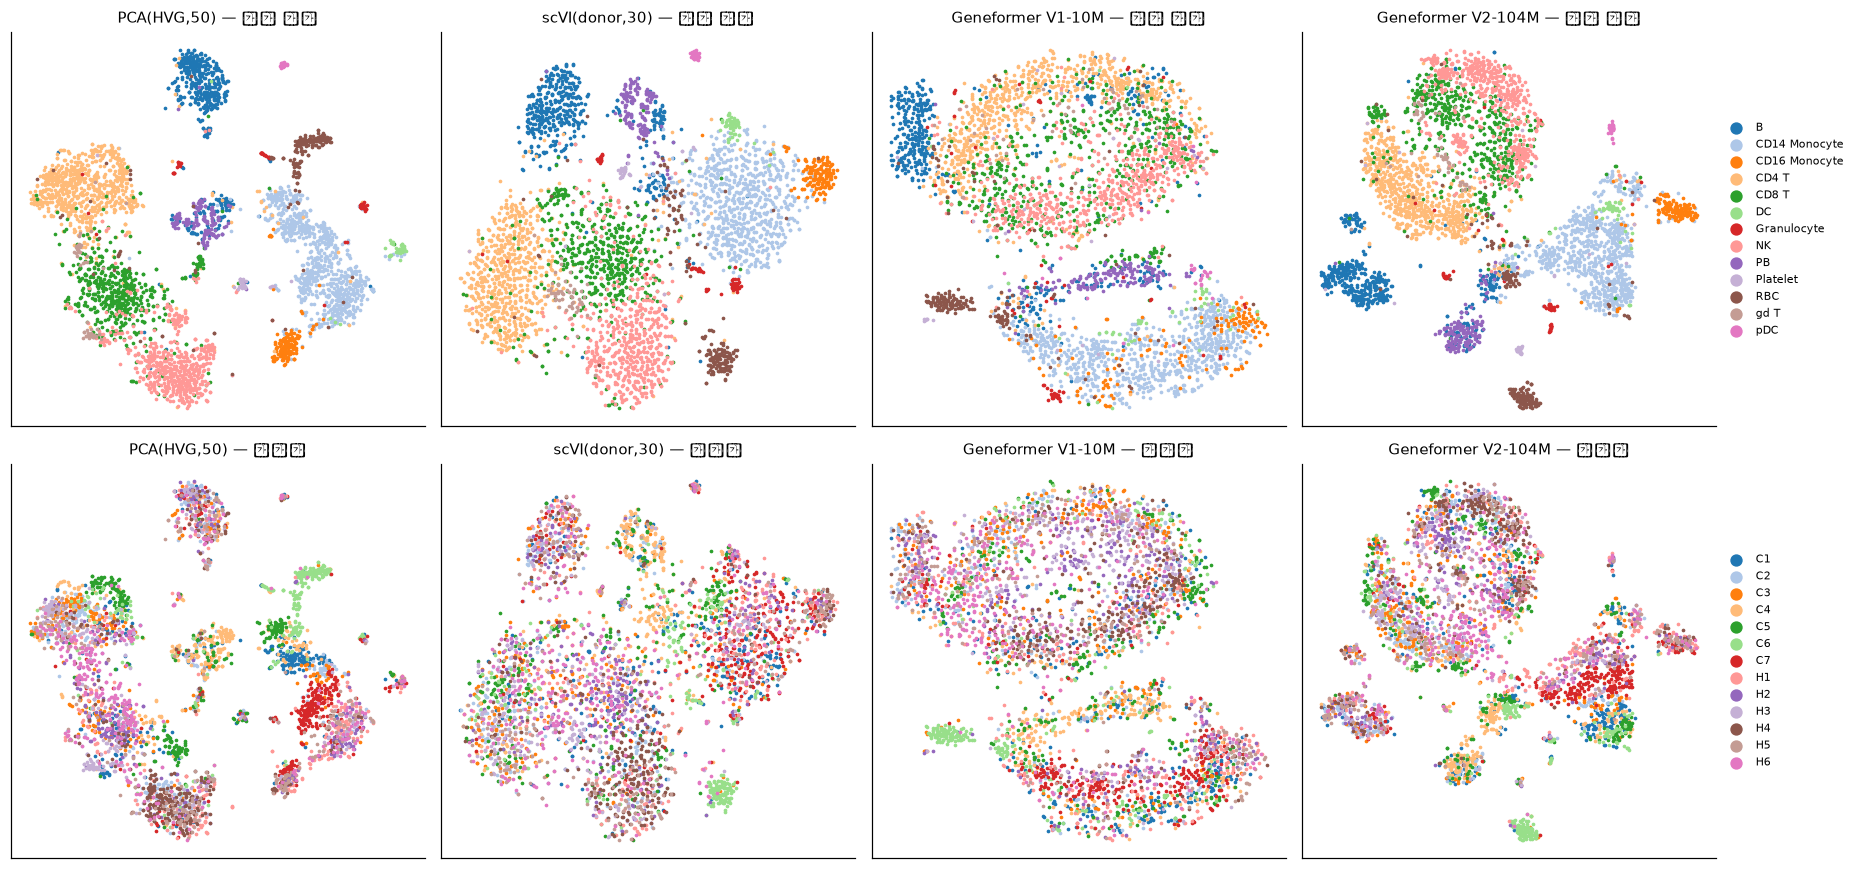

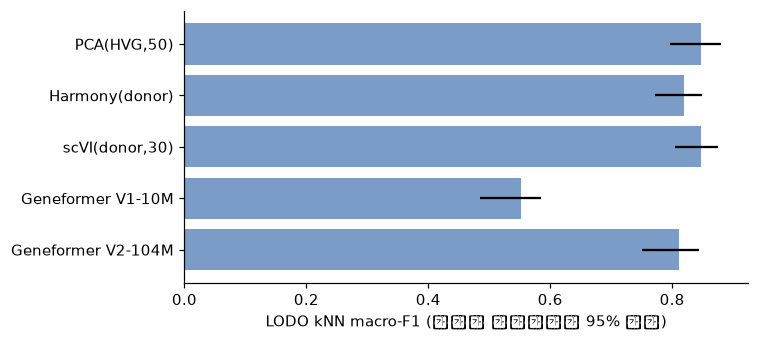

In [7]:
rs = np.random.default_rng(SEED).choice(sub.n_obs, min(4000, sub.n_obs), replace=False)
show = ["PCA(HVG,50)", "scVI(donor,30)", "Geneformer V1-10M", "Geneformer V2-104M"]
cmap_l = plt.get_cmap("tab20")
cmap_d = plt.get_cmap("tab20")
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for j, k in enumerate(show):
    Zn = prep(MAIN[k])[rs]
    xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Zn)
    for i, (arr, names, cm_) in enumerate([(labels[rs], class_names, cmap_l), (donors[rs], donor_names, cmap_d)]):
        ax = axes[i, j]
        for q, nm in enumerate(names):
            mk = arr == nm
            ax.scatter(xy[mk, 0], xy[mk, 1], s=2, color=cm_(q % 20), label=nm)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"{k} — {'세포 유형' if i == 0 else '기증자'}", fontsize=10)
        if j == 3:
            ax.legend(markerscale=5, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.2))
ks = list(R)
pts = [R[k]["f1"] for k in ks]
err = np.array([[R[k]["f1"] - ci(R[k]["f1_boot"])[0], ci(R[k]["f1_boot"])[1] - R[k]["f1"]] for k in ks]).T
ax.barh(ks, pts, xerr=err, color="#7a9cc6")
ax.set_xlabel("LODO kNN macro-F1 (기증자 부트스트랩 95% 구간)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 5. 민감도 분석 — 층 · 풀링 · 무작위 초기화
아래 변형은 **사전에 정한 주 비교가 아니다**. 어느 설정이 test 지표에서 높게 나왔다고 해서 그것을 "Geneformer의 성능"으로 보고하면 안 된다 (설정을 test로 고르는 것이 된다).
- 마지막 층 vs 마지막에서 두 번째 층, 평균 풀링 vs `<cls>`
- **무작위 초기화 V1**: 같은 구조·같은 토큰열(검출 집합과 순서)을 입력받고 사전학습만 없는 대조군 → 사전학습을 한 효과와 *토큰열 자체에 담긴 정보*를 나눠 보기 위한 것이다. 무작위 모델도 순위·토큰 ID·길이를 입력으로 받으므로 "검출 집합만"의 정보는 노트북 03의 ablation에서 따로 본다

In [8]:
VAR = {
    "V1 평균 마지막층": E["v1_mean_L-1"],
    "V1 무작위 초기화(평균,L-2)": E["v1rand_mean_L-2"],
    "V1 무작위 초기화(평균,마지막)": E["v1rand_mean_L-1"],
    "V2 평균 L-2": E["v2_mean_L-2"],
    "V2 평균 마지막": E["v2_mean_L-1"],
    "V2 cls 마지막": E["v2_cls_L-1"],
}
RV = {k: evaluate(v) for k, v in VAR.items()}
RR = {**R, **RV}
T_var = table(RR)
print(T_var.to_string())

                     macro-F1 (LODO kNN)         Δ vs PCA(HVG,50) 주요유형 macro-F1    정확도                  ARI    NMI ASW_label 기증자 식별 초과정확도(↓섞임) ASW_batch(↑섞임)         질병 LODO 균형정확도
방법                                                                                                                                                                                 
PCA(HVG,50)         0.847 [0.797, 0.880]                        —         0.873  0.887  0.577 [0.577~0.578]  0.695     0.586             0.268          0.915  0.751 [0.663, 0.835]
Harmony(donor)      0.819 [0.772, 0.849]  -0.028 [-0.040, -0.013]         0.843  0.860  0.601 [0.545~0.644]  0.683     0.583             0.060          0.928  0.602 [0.542, 0.668]
scVI(donor,30)      0.847 [0.804, 0.875]  +0.000 [-0.017, +0.024]         0.876  0.880  0.534 [0.531~0.535]  0.658     0.523             0.140          0.954  0.605 [0.550, 0.661]
Geneformer V1-10M   0.551 [0.485, 0.585]  -0.295 [-0.332, -0.265]         0.678  0.725  0.242 [0.239

## 6. 중심화의 영향
위 평가는 모든 임베딩을 평균 중심화한 뒤 코사인으로 쟀다. 중심화하지 않으면 Geneformer 임베딩의 큰 공통 성분 때문에 결과가 달라질 수 있다. 같은 평가를 중심화 없이 다시 한다 (LODO macro-F1만).

In [9]:
rows = []
for k, Z in {**MAIN, **VAR}.items():
    if "Geneformer" in k or k.startswith("V"):
        r0 = evaluate(Z, center=False)
        lo, hi = ci(r0["f1_boot"])
        rows.append({"방법": k, "중심화 O": f"{RR[k]['f1']:.3f}", "중심화 X": f"{r0['f1']:.3f} [{lo:.3f}, {hi:.3f}]"})
print(pd.DataFrame(rows).set_index("방법").to_string())
h = sub.n_obs // 2
for nm, key in [("V1 평균 L-2", "v1_mean_L-2"), ("V2 cls L-2", "v2_cls_L-2")]:
    cos = prep(E[key], center=False)
    print(f"{nm} 임베딩의 평균 코사인 유사도(서로 다른 무작위 세포 쌍, 중심화 전): {float((cos[:h] @ cos[h:2 * h].T).mean()):.3f}")

                    중심화 O                 중심화 X
방법                                             
Geneformer V1-10M   0.551  0.584 [0.514, 0.616]
Geneformer V2-104M  0.811  0.794 [0.732, 0.828]
V1 평균 마지막층          0.734  0.743 [0.686, 0.778]
V1 무작위 초기화(평균,L-2)  0.354  0.313 [0.264, 0.335]
V1 무작위 초기화(평균,마지막)  0.357  0.304 [0.259, 0.323]
V2 평균 L-2           0.764  0.752 [0.683, 0.791]
V2 평균 마지막           0.833  0.821 [0.763, 0.850]
V2 cls 마지막          0.825  0.807 [0.741, 0.843]
V1 평균 L-2 임베딩의 평균 코사인 유사도(서로 다른 무작위 세포 쌍, 중심화 전): 0.953
V2 cls L-2 임베딩의 평균 코사인 유사도(서로 다른 무작위 세포 쌍, 중심화 전): 0.991


## 7. 해석과 한계
아래는 이 실행(seed 0, 10,400세포, 13명)에서 읽은 내용이다. **표를 직접 확인한다.**

**주 비교 (사전 지정한 5종)**
- **PCA(HVG)와 scVI는 구분되지 않는다**: LODO macro-F1 0.847 [0.797, 0.880] 대 0.847 (Δ +0.000 [−0.017, +0.024]). Harmony는 0.819로 작게 낮고 구간이 0을 포함하지 않는다(Δ −0.028 [−0.040, −0.013]).
- **zero-shot Geneformer는 이 데이터·이 절차에서 PCA를 이기지 못했다.** V1-10M 0.551 (Δ −0.295 [−0.332, −0.265]), V2-104M 0.811 (Δ −0.036 [−0.064, −0.018]). V2는 PCA에 가깝지만 구간상 낮다. 세포 300개 이상 유형 8종만의 macro-F1에서도 순서는 같다(PCA 0.873, scVI 0.876, Harmony 0.843, V2 0.827, V1 0.678). 이 결과는 Kedzierska et al.의 방향(일부 조건에서 단순한 방법이 FM을 앞선다)과 같으나 **다른 데이터·다른 절차의 한 사례**일 뿐이다.
- 세포 유형별 재현율(3.1절): V1은 작은 유형에서 크게 무너진다(pDC 0.25, DC 0.19, CD16 단핵구 0.27, 혈소판 0.31, γδ T 0.01). V2는 pDC 0.95, CD16 0.89로 회복한다. γδ T는 **모든 방법이 낮고**(PCA 0.44) 이 유형 139개 중 136개가 정상 기증자 세포라 기증자 단위 분할에서 학습 예가 한쪽 질병 상태로 쏠린다. macro-F1은 이런 작은 클래스에 민감하다.
- KMeans ARI/NMI도 같은 순서다(ARI: PCA 0.577, V2 0.378, V1 0.242). k를 정답 클래스 수로 준 낙관적 설정이며, 괄호의 범위는 KMeans 초기화 시드(3개)에 대한 것일 뿐 데이터 변동을 반영하지 않는다.

**설정 민감도는 방법 간 차이만큼 크다 (5절)**
- V1은 **마지막 층 평균**이 0.734로, 사전 지정한 마지막에서 두 번째 층(0.551)보다 0.18 높다. V2는 평균 마지막 층 0.833, cls 마지막 층 0.825, 평균 L-2 0.764다. 즉 "Geneformer의 성능"은 하나의 숫자가 아니다. 사후에 가장 좋은 설정을 골라 보고하면 test로 설정을 고르는 것이다 (V2 평균 마지막 층 0.833은 PCA 대비 Δ −0.014 [−0.037, −0.004]이지만 사후 선택이므로 비교 근거로 쓰지 않는다).
- **무작위 초기화 V1**(같은 구조·같은 토큰열): 0.354 [0.293, 0.383]. 같은 층끼리 보면 사전학습을 한 쪽이 L-2에서 +0.20 (0.354→0.551), 마지막 층에서 +0.38 (0.357→0.734)이다. 무작위 가중치 모델도 순위·토큰 ID·길이를 입력으로 받으므로, **무작위 모델이 0.35를 얻는다는 것은 "토큰열 자체(검출 집합과 순서)"에 상당한 세포 유형 신호가 있다는 뜻**이다. 그중 검출 집합과 카운트 순위가 각각 얼마나 기여하는지는 노트북 03의 ablation에서 따로 본다.
- 중심화 방식은 영향이 작다(V1 L-2: fold 훈련 평균 중심화 0.551 / 중심화 안 함 0.584, V2: 0.811 / 0.794; 구간이 겹친다). 중심화 전 임의의 세포 쌍 코사인 유사도 평균이 V1 0.953, V2 cls 0.991로 높아(임베딩이 한 방향으로 쏠림, anisotropy) **코사인 유사도의 절댓값은 해석하면 안 된다.**

**배치 혼합 — 보존 지표 없이는 의미가 없고, 지표끼리도 어긋난다**
- 같은 세포 유형 안에서 기증자를 맞히는 초과 정확도(작을수록 섞임): Harmony 0.060 < scVI 0.140 < V1 0.172 < V2 0.253 < PCA 0.268. 그런데 **무작위 초기화 V1도 0.060**이다. 정보가 없으면 기증자도 안 보인다. 섞임은 반드시 세포 유형 보존과 함께 읽어야 한다.
- scib식 ASW_batch(세포별 1−|s|)는 PCA 0.915 < Harmony 0.928 < V1 0.937 < scVI 0.954 < V2 0.955(무작위 초기화 V1 0.976)로 범위가 좁고(주 비교 5종에서 0.04), 순서가 위 kNN 기반 지표와 맞지 않는다(Harmony는 kNN 기반 지표에서 가장 섞였지만 ASW_batch에서는 scVI·V2보다 낮다). 이 설정(13개 배치, 세포 유형 내)에서는 ASW_batch가 변별력이 약하다고 읽는다.

**질병 신호 — 배치 보정이 생물학을 지울 수 있다**
- 질병은 기증자에 완전히 겹친다. 같은 세포 유형 안에서 다른 기증자로 학습해 held-out 기증자의 질병을 맞히는 균형 정확도는 PCA 0.751 [0.663, 0.835], V2 0.764 [0.675, 0.849], V1 0.705인데 **Harmony 0.602 [0.542, 0.668], scVI 0.605 [0.550, 0.661]**로 낮다(구간이 일부 겹치므로 방향성으로만 읽는다). 기증자를 "배치"로 보정하면 기증자 수준의 생물학적 차이(질병)도 함께 줄어들 수 있다는 가설과 일치하지만, 이 데이터로는 배치 효과와 질병 효과를 분리할 수 없다.

**한계**
- 단일 데이터셋(Seq-Well, 얕음, 13명), 라벨은 원 논문 주석이다. 이 데이터가 Geneformer 사전학습 코퍼스에 포함되었는지는 확인하지 못했다.
- baseline의 하이퍼파라미터(HVG 2,000, PCA 50, scVI 150 에폭·잠재 30, kNN k=15)는 조정하지 않았다. 그래서 baseline이 최적이 아닐 수 있다. 반대로 FM은 **zero-shot kNN만** 봤고 미세조정/선형 probe는 보지 않았다. 결론은 "zero-shot 임베딩 + kNN"에 한정된다.
- PCA/Harmony/scVI는 held-out 기증자의 세포까지 비지도로 적합했다(transductive; PCA의 HVG·축에 held-out 기증자 세포가 들어 있다). Harmony/scVI는 기증자 라벨을 사용했고 Geneformer는 쓰지 않았다. 반면 LODO 분류의 평균 중심화는 fold별 훈련 기증자 평균만 썼다.
- 부트스트랩은 13명의 기증자를 재표본한 **조건부 구간**이다(예측을 재표본할 뿐 임베딩·분류기를 다시 적합하지 않음). 기증자가 적어 구간이 좁게 느껴져도 일반화 가능성은 별개다. 서로 다른 지표 사이의 다중 비교 보정은 하지 않았다.